## Understanding Sinudsoidal Encoding

In [8]:
import matplotlib.pyplot as plt
from math import sin, cos
import numpy as np
import seaborn as sns

In [12]:
def pos_encoding(n: int, d: int):
    """
    Given length and dim, create pos encoding vector output
    """
    pos_vector = np.zeros(shape = (n, d)) 

    for pos in range(n):
        for i in range(0, d // 2):
            pos_vector[pos][i*2] = sin(pos / 1e4 ** (2 * i / d))
            pos_vector[pos][i*2 + 1] = cos(pos / 1e4 ** (2 * i / d))
    
    return pos_vector
                                           
    




In [19]:
pos_vector = pos_encoding(n = 100, d = 256)

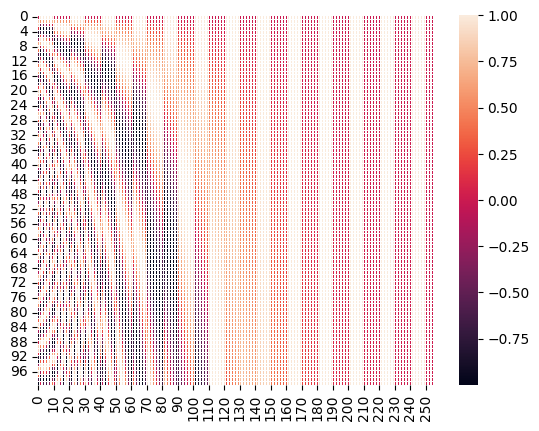

In [20]:
ax = sns.heatmap(pos_vector, linewidth=0.5)
plt.show()

We can understand this by drawing parallel to bits

0   0   0   ->  0

0   0   1   ->  1

0   1   0   ->  2

0   1   1   ->  3

1   0   0   ->  4

1   0   1   ->  5

1   1   0   ->  6

Each bit pos changes behavior at a certain frequency: The first bit oscillates every other pos; the second bit oscillates every 2 pos and the third, every 4 pos. The same can be imagined with the above sinusoidal pos encodings. The first dim oscillates wildly, oscillation as we cover the remaining dims. This basically means that regardless of the length of the input sequence, the behavior of the dims is based on the relative positions of the tokens.